<a href="https://colab.research.google.com/github/seonilj/ml-neural-networks-for-neuroscience/blob/main/assignments/hw1-neural-tuning/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import h5py
from scipy.io import loadmat
from scipy.optimize import curve_fit # step 6
from scipy.optimize import curve_fit # step 7

#Step 1: Data Loading and Checkup
(Part 1 preparation: Load data and inspect its structure)

In [2]:
# 1. Check MATLAB files
data_dir = Path("/content/sample_data")
mat_files = sorted(data_dir.rglob("*_spikes.mat"))

print("MATLAB files found:", len(mat_files))
for path in mat_files:
    print(path.name)

assert len(mat_files) > 0, "No MATLAB files exist."

MATLAB files found: 5
105l001p16_spikes.mat
106r001p26_spikes.mat
106r002p70_spikes.mat
107l002p67_spikes.mat
107l003p143_spikes.mat


In [3]:
# 2. Select 'one' session
target_name = "105l001p16_spikes.mat"
matches = [path for path in mat_files if path.name == target_name]

if matches:
    mat_path = matches[0]
else:
    raise FileNotFoundError(f"{target_name} was not found.")

print("Selected session:", mat_path.name)

Selected session: 105l001p16_spikes.mat


In [4]:
# 3. Load: MATLAB v7.3 data
with h5py.File(mat_path, "r") as f:
    stim = np.asarray(f["stim"]).squeeze() # average spike count per neuron & stimulus direction
    spike_refs = np.asarray(f["spikes"]).squeeze()

    spikes_1 = np.asarray(f[spike_refs[0]]) # original spikes data
    spikes_2 = np.asarray(f[spike_refs[1]])

# Step 2: Spike Count & Tuning Curve Preparation
(Part 1: Calculate spike count per trial and average per stimulus)

In [5]:
# 4. Check the data
print("Spike dataset 1 shape:", spikes_1.shape)
print("Spike dataset 2 shape:", spikes_2.shape)
print("Trials number:", stim.size)
print("Unique stimulus orientations:", np.unique(stim))

Spike dataset 1 shape: (3200, 1280, 159)
Spike dataset 2 shape: (3200, 1280, 25)
Trials number: 3200
Unique stimulus orientations: [1. 2. 3. 4. 5. 6. 7. 8.]


In [6]:
# 5. Calculate the 'total spike count' (for each trial)

response_1 = spikes_1.sum(axis=1) # total spike count for each trial
response_2 = spikes_2.sum(axis=1)

print("Dataset 1 response shape:", response_1.shape)
print("Dataset 2 response shape:", response_2.shape)

assert response_1.shape == (stim.size, spikes_1.shape[2])
assert response_2.shape == (stim.size, spikes_2.shape[2])

Dataset 1 response shape: (3200, 159)
Dataset 2 response shape: (3200, 25)


In [7]:
# 6. Count trials (for each stimulus code)
orientations = np.unique(stim)

for orientation in orientations:
    count = np.count_nonzero(stim == orientation)
    print(f"Stimulus {orientation:g}: {count} trials")

# 7. Calculate mean response (for each neuron and stimulus code)
mean_response_1 = np.array([
    response_1[stim == orientation].mean(axis=0)
    for orientation in orientations
]).T # Average spike count per neuron and stimulus direction

mean_response_2 = np.array([
    response_2[stim == orientation].mean(axis=0)
    for orientation in orientations
]).T

print("\nDataset 1 mean response shape:", mean_response_1.shape)
print("Dataset 2 mean response shape:", mean_response_2.shape)

assert np.isfinite(mean_response_1).all()
assert np.isfinite(mean_response_2).all()

Stimulus 1: 400 trials
Stimulus 2: 400 trials
Stimulus 3: 400 trials
Stimulus 4: 400 trials
Stimulus 5: 400 trials
Stimulus 6: 400 trials
Stimulus 7: 400 trials
Stimulus 8: 400 trials

Dataset 1 mean response shape: (159, 8)
Dataset 2 mean response shape: (25, 8)


# Step 3: Exploratory Tuning Curves & Neuron Selection
(Part 1: Visualize tuning curves, select neurons)

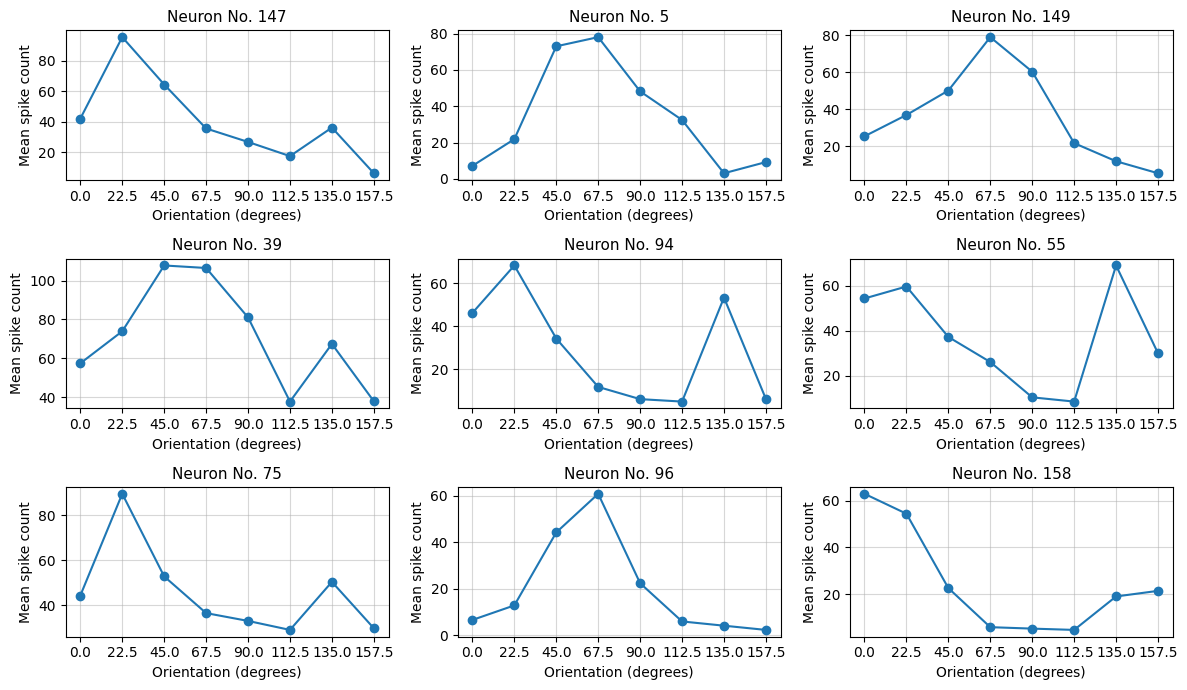

Candidate neurons indices: [147   5 149  39  94  55  75  96 158]


In [8]:
# 8. Plot candidate tuning curves

response_range = (
    mean_response_1.max(axis=1) - mean_response_1.min(axis=1)
)

candidate_neurons = np.argsort(response_range)[::-1][:9]

fig, axes = plt.subplots(3, 3, figsize=(12, 7))
axes = axes.flatten()

orientations_deg = (orientations - 1) * 22.5

for ax, neuron in zip(axes, candidate_neurons):
    ax.plot(orientations_deg, mean_response_1[neuron], marker="o", lw=1.5)
    ax.set_title(f"Neuron No. {neuron}", fontsize=11)
    ax.set_xlabel("Orientation (degrees)")
    ax.set_ylabel("Mean spike count")
    ax.set_xticks(orientations_deg)
    ax.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

print("Candidate neurons indices:", candidate_neurons)

In [9]:
# Select one neuron (preparation for further analysis)
selected_neuron = 149

# Mean spike count for each stimulus code
selected_response = mean_response_1[selected_neuron]

print("Selected neuron:", selected_neuron)
print("Mean spike counts:", selected_response)

Selected neuron: 149
Mean spike counts: [25.3175 36.8275 50.0275 78.8825 60.225  21.6175 11.8375  5.3525]


# Step 4: Orientation Mapping and Firing Rate Calculation
(Part 1 & 2 prepartion: Verify actual angles and convert to spikes/s)

In [10]:
# 9. Check the stimulus codes & each trial counts
for code in np.unique(stim):
    print(f"Code {code:g}: {np.count_nonzero(stim == code)} trials")
    # each 400 trials; total 3200 trials (matching to README.md)

Code 1: 400 trials
Code 2: 400 trials
Code 3: 400 trials
Code 4: 400 trials
Code 5: 400 trials
Code 6: 400 trials
Code 7: 400 trials
Code 8: 400 trials


In [11]:
# Convert: mean spike counts -> firing rates
selected_rate = selected_response / 1.28

print(f"Mean firing rates (spikes/s):\n {selected_rate}")

Mean firing rates (spikes/s):
 [19.77929688 28.77148438 39.08398438 61.62695312 47.05078125 16.88867188
  9.24804688  4.18164062]


Stimulus orientations (degrees):
 [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]


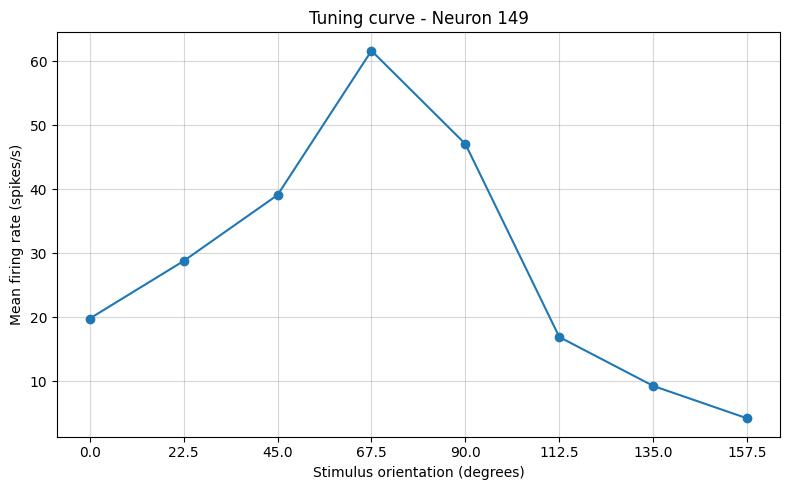

In [12]:
# 9. Convert: stimulus codes -> actual orientations in degrees

orientations_deg = (orientations - 1) * 22.5

print(f"Stimulus orientations (degrees):\n {orientations_deg}")

# Plot the selected neuron's tuning curve
plt.figure(figsize=(8, 5))

plt.plot(
    orientations_deg,
    selected_rate,
    marker="o",
    lw=1.5
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Tuning curve - Neuron 149")
plt.xticks(orientations_deg)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

# Step 5: Polynomial Regression
(Part 2: 1st, 3rd, 4th, and 7th-degree models, graphs, and MSE)

Degree 1: MSE = 279.0867
Degree 3: MSE = 72.2633
Degree 4: MSE = 24.7955
Degree 7: MSE = 0.0000


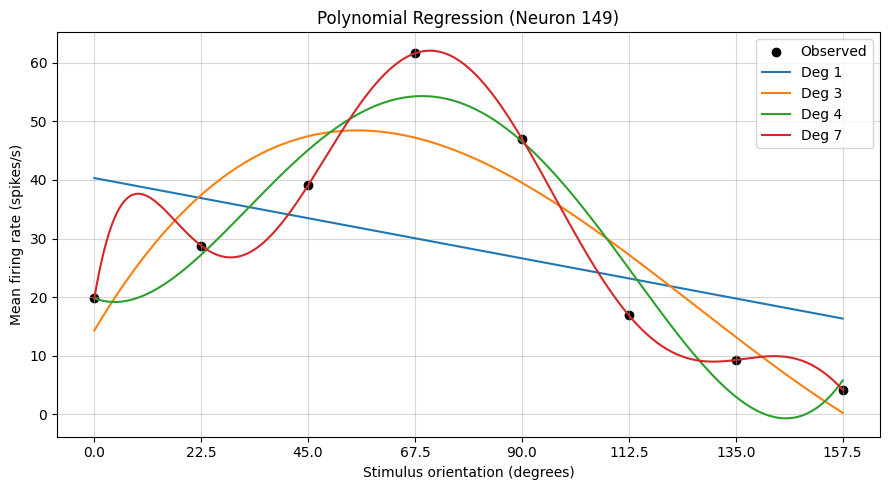

In [13]:
# Polynomial models' degrees
degrees = [1, 3, 4, 7]

# Store fitted models & its MSE values
polynomial_models = {}
polynomial_mse = {}

# Smooth x-values for plotting the fitted curves
theta_smooth = np.linspace(
    orientations_deg.min(),
    orientations_deg.max(),
    300
)

# Fit each polynomial model
for degree in degrees:
    model = np.polynomial.Polynomial.fit(
        orientations_deg,
        selected_rate,
        deg=degree
    )

    # Predictions at the original stimulus orientations
    predicted_rate = model(orientations_deg)

    # Mean Squared Error (MSE)
    mse = np.mean((selected_rate - predicted_rate) ** 2)

    polynomial_models[degree] = model
    polynomial_mse[degree] = mse

    print(f"Degree {degree}: MSE = {mse:.4f}")

# Plot the data and fitted curves
plt.figure(figsize=(9, 5))

plt.scatter(
    orientations_deg, selected_rate,
    color="black",
    label="Observed"
)

for deg in degrees:
    plt.plot(
        theta_smooth,
        polynomial_models[deg](theta_smooth),
        label=f"Deg {deg}"
    )

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Polynomial Regression (Neuron 149)")
plt.xticks(orientations_deg)
plt.grid(True, alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

# Step 6: Gaussian Nonlinear Regression
(Part 3: Gaussian fit, parameters, and MSE)

In [14]:
# Gaussian tuning curve
def gaussian_tuning(theta, B, A, mu, sigma):
    return B + A * np.exp(
        -((theta - mu) ** 2) / (2 * sigma ** 2)
    )

# Initial parameter estimates
initial_guess = [
    selected_rate.min(),
    selected_rate.max() - selected_rate.min(),
    orientations_deg[np.argmax(selected_rate)],
    30.0
    ]

# Fit the Gaussian model
params, covariance = curve_fit(
    gaussian_tuning,
    orientations_deg,
    selected_rate,
    p0=initial_guess,
    bounds=(
        [0, 0, 0, 1],
        [np.inf, np.inf, 180, 180]
    ),
    maxfev=20000
    )

B_fit, A_fit, mu_fit, sigma_fit = params

Baseline B: 7.7139 spikes/s
Amplitude A: 50.5491 spikes/s
Preferred orientation mu: 66.0368 degrees
Tuning width sigma: 29.3941 degrees
Gaussian MSE: 26.2097


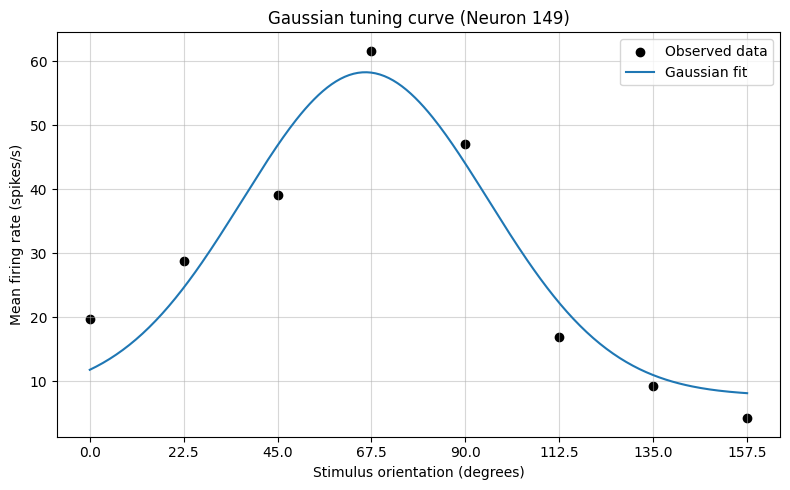

In [15]:
# Predicted responses and MSE
gaussian_predicted = gaussian_tuning(
    orientations_deg, *params
)

gaussian_mse = np.mean(
    (selected_rate - gaussian_predicted) ** 2
)

print(f"Baseline B: {B_fit:.4f} spikes/s")
print(f"Amplitude A: {A_fit:.4f} spikes/s")
print(f"Preferred orientation mu: {mu_fit:.4f} degrees")
print(f"Tuning width sigma: {sigma_fit:.4f} degrees")
print(f"Gaussian MSE: {gaussian_mse:.4f}")

# Plot the observed data and fitted Gaussian
theta_smooth = np.linspace(
    orientations_deg.min(), orientations_deg.max(),
    300
)

plt.figure(figsize=(8, 5))

plt.scatter(
    orientations_deg, selected_rate,
    color="black",
    label="Observed data"
)

plt.plot(
    theta_smooth,
    gaussian_tuning(theta_smooth, *params),
    label="Gaussian fit"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Gaussian tuning curve (Neuron 149)")
plt.xticks(orientations_deg)
plt.grid(alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

# Step 7: Circular Tuning Model (von Mises)
(Part 4: Incorporate circular properties, model fitting, and comparison)

In [16]:
# Define: von Mises tuning function
def von_mises_tuning(theta, B, A, mu, kappa):
    return B + A * np.exp(
        kappa * np.cos(2 * np.deg2rad(theta - mu))
    )

# Initial parameter guesses
initial_guess_vm = [
    selected_rate.min(),
    (selected_rate.max() - selected_rate.min()) / np.e,
    orientations_deg[np.argmax(selected_rate)],
    1.0
]

# Fit the model to the observed data
params_vm, covariance_vm = curve_fit(
    von_mises_tuning,
    orientations_deg,
    selected_rate,
    p0=initial_guess_vm,
    bounds=([0, 0, 0, 0.001],
            [np.inf, np.inf, 180, 10]),
    maxfev=20000
)

# Extract the fitted parameters
B_vm, A_vm, mu_vm, kappa_vm = params_vm
print(params_vm)

[ 0.12777522 22.63261942 66.5493577   0.96375165]


Baseline B: 0.1278 spikes/s
Scale parameter A: 22.6326
Preferred orientation mu: 66.5494 degrees
Concentration kappa: 0.9638
von Mises MSE: 25.4922


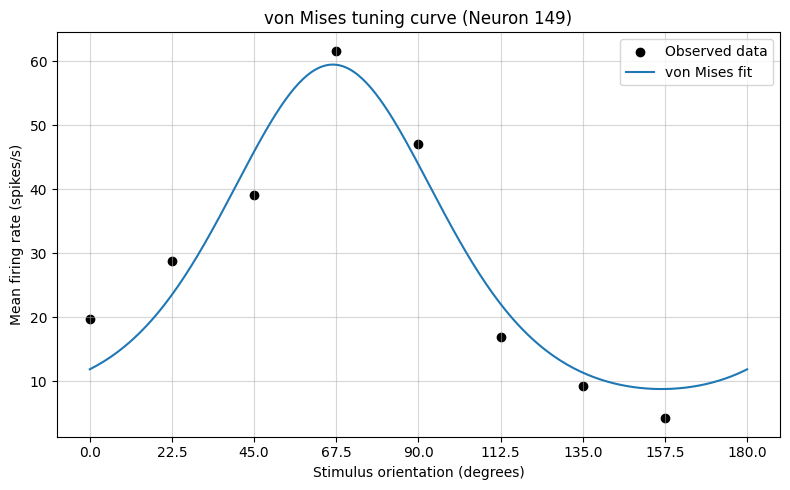

In [17]:
# Calculate predicted responses and MSE
vm_predicted = von_mises_tuning(
    orientations_deg, *params_vm
)
vm_mse = np.mean(
    (selected_rate - vm_predicted) ** 2
)

print(f"Baseline B: {B_vm:.4f} spikes/s")
print(f"Scale parameter A: {A_vm:.4f}")
print(f"Preferred orientation mu: {mu_vm:.4f} degrees")
print(f"Concentration kappa: {kappa_vm:.4f}")
print(f"von Mises MSE: {vm_mse:.4f}")

# Plot the observed data and fitted von Mises curve
theta_smooth_vm = np.linspace(0, 180, 300)

plt.figure(figsize=(8, 5))

plt.scatter(
    orientations_deg, selected_rate,
    color="black",
    label="Observed data"
)

plt.plot(
    theta_smooth_vm,
    von_mises_tuning(theta_smooth_vm, *params_vm),
    label="von Mises fit"
)

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("von Mises tuning curve (Neuron 149)")
plt.xticks(np.arange(0, 181, 22.5))
plt.grid(alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
# Compare Gaussian vs. von Mises models
print(f"Gaussian MSE: {gaussian_mse:.4f}")
print(f"von Mises MSE: {vm_mse:.4f}")

Gaussian MSE: 26.2097
von Mises MSE: 25.4922


# Step 8: Select two neurons with high response variability
(Part 5:	Model comparison table, 2 additional neurons, and generalization analysis)

In [19]:
# Step 8.2: Select two neurons with high response variability

residuals = np.zeros_like(response_1, dtype=float)

for code in orientations:
    mask = (stim == code)

    orientation_mean = response_1[mask].mean(axis=0)

    residuals[mask] = response_1[mask] - orientation_mean

# Calculate response variability for each neuron
neuron_variability = np.mean(residuals ** 2, axis=0)

# Exclude the neuron already analyzed (Neuron 149)
neuron_variability[selected_neuron] = -1

# Select two neurons with the highest variability
noisy_neurons = np.argsort(neuron_variability)[-2:][::-1]

print("Selected neurons:", noisy_neurons)
print("Variability scores:", neuron_variability[noisy_neurons])

Selected neurons: [ 75 106]
Variability scores: [197.42270469 188.84624375]


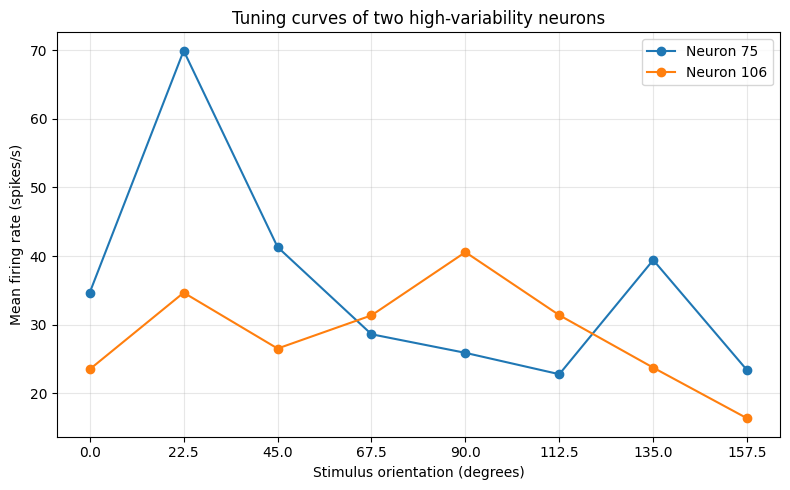

In [20]:
# Plot tuning curves for the two selected neurons

plt.figure(figsize=(8, 5))

for neuron in noisy_neurons:
    mean_rate = mean_response_1[neuron] / 1.28

    plt.plot(
        orientations_deg,
        mean_rate,
        marker="o",
        label=f"Neuron {neuron}"
    )

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Tuning curves of two high-variability neurons")
plt.xticks(orientations_deg)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Step 8.4: Compare three models on two noisy neurons

from scipy.optimize import curve_fit

def linear_tuning(theta, a, b):
    return a * theta + b

def gaussian_tuning(theta, B, A, mu, sigma):
    return B + A * np.exp(
        -((theta - mu) ** 2) / (2 * sigma ** 2)
    )

def von_mises_tuning(theta, B, A, mu, kappa):
    return B + A * np.exp(
        kappa * np.cos(2 * np.deg2rad(theta - mu))
    )

results = {}

for neuron in noisy_neurons:
    # Mean firing rate for this neuron at each orientation
    neuron_rate = np.array([
        response_1[stim == code, neuron].mean()
        for code in orientations
    ]) / 1.28

    # Linear model
    linear_params = np.polyfit(
        orientations_deg, neuron_rate, deg=1
    )
    linear_pred = np.polyval(
        linear_params, orientations_deg
    )
    linear_mse = np.mean((neuron_rate - linear_pred) ** 2)

    # Gaussian model
    gaussian_initial = [
        neuron_rate.min(),
        neuron_rate.max() - neuron_rate.min(),
        orientations_deg[np.argmax(neuron_rate)],
        30.0
    ]

    gaussian_params, _ = curve_fit(
        gaussian_tuning,
        orientations_deg,
        neuron_rate,
        p0=gaussian_initial,
        bounds=([0, 0, 0, 1], [np.inf, np.inf, 180, 180]),
        maxfev=20000
    )
    gaussian_pred = gaussian_tuning(
        orientations_deg, *gaussian_params
    )
    gaussian_mse_noisy = np.mean(
        (neuron_rate - gaussian_pred) ** 2
    )

    # von Mises model
    vm_initial = [
        neuron_rate.min(),
        (neuron_rate.max() - neuron_rate.min()) / np.e,
        orientations_deg[np.argmax(neuron_rate)],
        1.0
    ]

    vm_params, _ = curve_fit(
        von_mises_tuning,
        orientations_deg,
        neuron_rate,
        p0=vm_initial,
        bounds=([0, 0, 0, 0.001], [np.inf, np.inf, 180, 10]),
        maxfev=20000
    )
    vm_pred = von_mises_tuning(
        orientations_deg, *vm_params
    )
    vm_mse_noisy = np.mean(
        (neuron_rate - vm_pred) ** 2
    )

    results[neuron] = {
        "rate": neuron_rate,
        "linear_mse": linear_mse,
        "gaussian_mse": gaussian_mse_noisy,
        "von_mises_mse": vm_mse_noisy,
        "linear_params": linear_params,
        "gaussian_params": gaussian_params,
        "von_mises_params": vm_params
    }

    print(f"\nNeuron {neuron}")
    print(f"Linear MSE: {linear_mse:.4f}")
    print(f"Gaussian MSE: {gaussian_mse_noisy:.4f}")
    print(f"von Mises MSE: {vm_mse_noisy:.4f}")


Neuron 75
Linear MSE: 147.7687
Gaussian MSE: 22.9727
von Mises MSE: 23.1293

Neuron 106
Linear MSE: 45.0339
Gaussian MSE: 21.7711
von Mises MSE: 21.7582


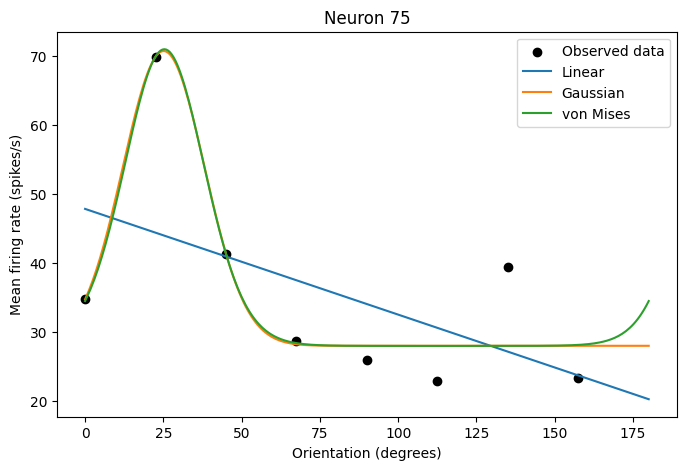

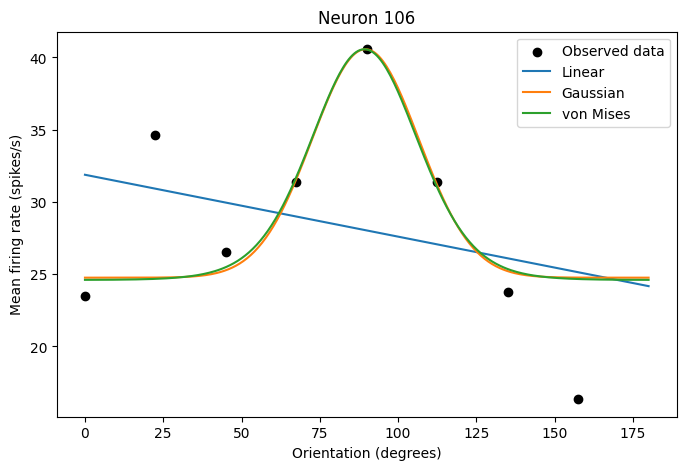

In [22]:
# Step 8.5: Plot model fits for two noisy neurons

theta_smooth = np.linspace(0, 180, 300)

for neuron in noisy_neurons:
    rate = results[neuron]["rate"]

    plt.figure(figsize=(8, 5))

    plt.scatter(orientations_deg, rate, color="black",
                label="Observed data")

    plt.plot(theta_smooth,
             np.polyval(results[neuron]["linear_params"], theta_smooth),
             label="Linear")

    plt.plot(theta_smooth,
             gaussian_tuning(theta_smooth, *results[neuron]["gaussian_params"]),
             label="Gaussian")

    plt.plot(theta_smooth,
             von_mises_tuning(theta_smooth, *results[neuron]["von_mises_params"]),
             label="von Mises")

    plt.title(f"Neuron {neuron}")
    plt.xlabel("Orientation (degrees)")
    plt.ylabel("Mean firing rate (spikes/s)")
    plt.legend()
    plt.show()